# Part 2: Real-World Logistic Regression Project

## 1. Dataset Loading and Exploration

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer

In [2]:
# Load dataset
cancer = load_breast_cancer()

# Features
X = pd.DataFrame(
    cancer.data,
    columns=cancer.feature_names
)

# Original target
y_original = pd.Series(cancer.target)

# Re-encode target:
# 1 = Malignant
# 0 = Benign
y = (y_original == 0).astype(int)

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [3]:
print("Dataset shape:", X.shape)
print("Target shape:", y.shape)

Dataset shape: (569, 30)
Target shape: (569,)


In [4]:
X.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [5]:
X.info()

<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 30 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         569 non-null

In [6]:
X.describe().T

,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127292,3.524049,6.981000,11.700000,13.370000,15.780000,28.11000
mean texture,569.0,19.289649,4.301036,9.710000,16.170000,18.840000,21.800000,39.28000
mean perimeter,569.0,91.969033,24.298981,43.790000,75.170000,86.240000,104.100000,188.50000
mean area,569.0,654.889104,351.914129,143.500000,420.300000,551.100000,782.700000,2501.00000
mean smoothness,569.0,0.096360,0.014064,0.052630,0.086370,0.095870,0.105300,0.16340
mean compactness,569.0,0.104341,0.052813,0.019380,0.064920,0.092630,0.130400,0.34540
mean concavity,569.0,0.088799,0.079720,0.000000,0.029560,0.061540,0.130700,0.42680
mean concave points,569.0,0.048919,0.038803,0.000000,0.020310,0.033500,0.074000,0.20120
mean symmetry,569.0,0.181162,0.027414,0.106000,0.161900,0.179200,0.195700,0.30400
mean fractal dimension,569.0,0.062798,0.007060,0.049960,0.057700,0.061540,0.066120,0.09744


In [7]:
print("Missing values:", X.isnull().sum().sum())
print("Duplicate rows:", X.duplicated().sum())

Missing values: 0
Duplicate rows: 0


In [8]:
print(y.value_counts())

print("\nClass percentages:")
print(y.value_counts(normalize=True) * 100)

0    357
1    212
Name: count, dtype: int64

Class percentages:
0    62.741652
1    37.258348
Name: proportion, dtype: float64


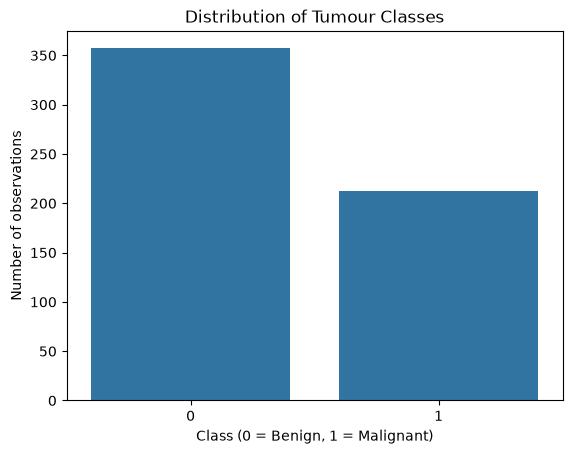

In [9]:
sns.countplot(x=y)

plt.title("Distribution of Tumour Classes")
plt.xlabel("Class (0 = Benign, 1 = Malignant)")
plt.ylabel("Number of observations")
plt.show()

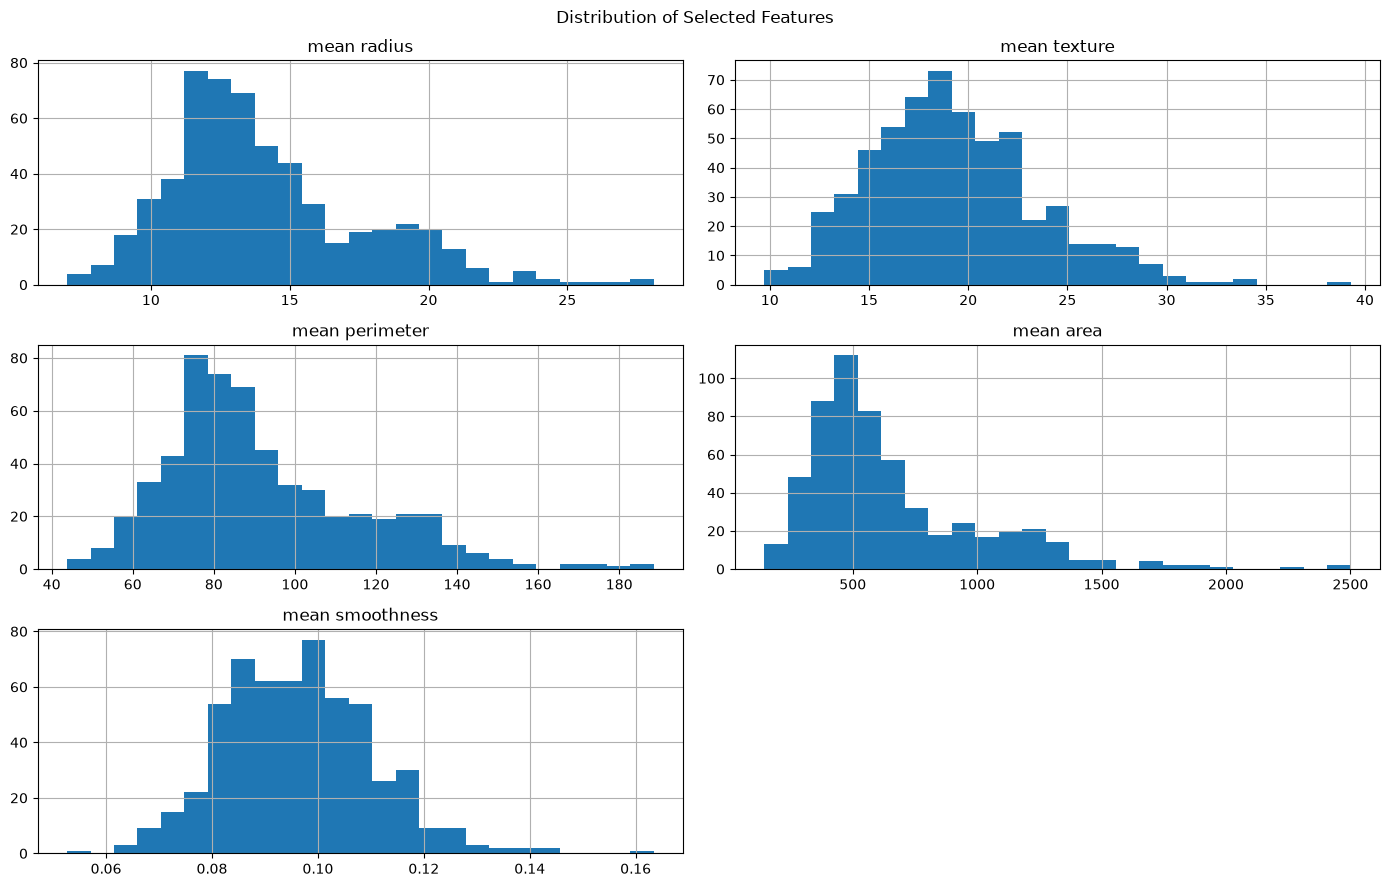

In [10]:
selected_features = [
    "mean radius",
    "mean texture",
    "mean perimeter",
    "mean area",
    "mean smoothness"
]

X[selected_features].hist(
    figsize=(14, 9),
    bins=25
)

plt.suptitle("Distribution of Selected Features")
plt.tight_layout()
plt.show()

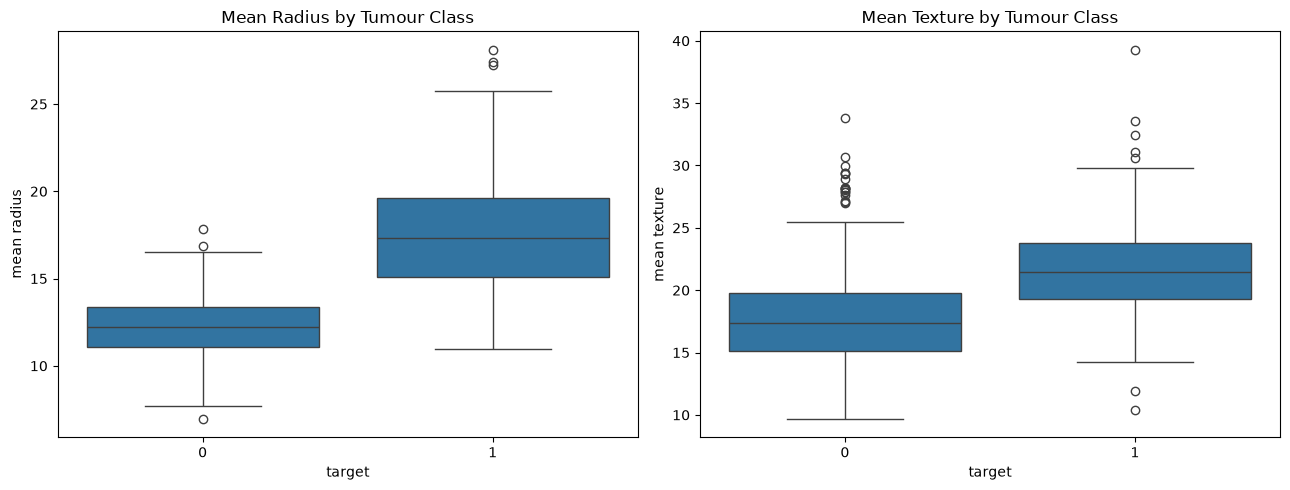

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.boxplot(
    data=pd.DataFrame({"mean radius": X["mean radius"], "target": y}),
    x="target",
    y="mean radius",
    ax=axes[0]
)

sns.boxplot(
    data=pd.DataFrame({"mean texture": X["mean texture"], "target": y}),
    x="target",
    y="mean texture",
    ax=axes[1]
)

axes[0].set_title("Mean Radius by Tumour Class")
axes[1].set_title("Mean Texture by Tumour Class")

plt.tight_layout()
plt.show()

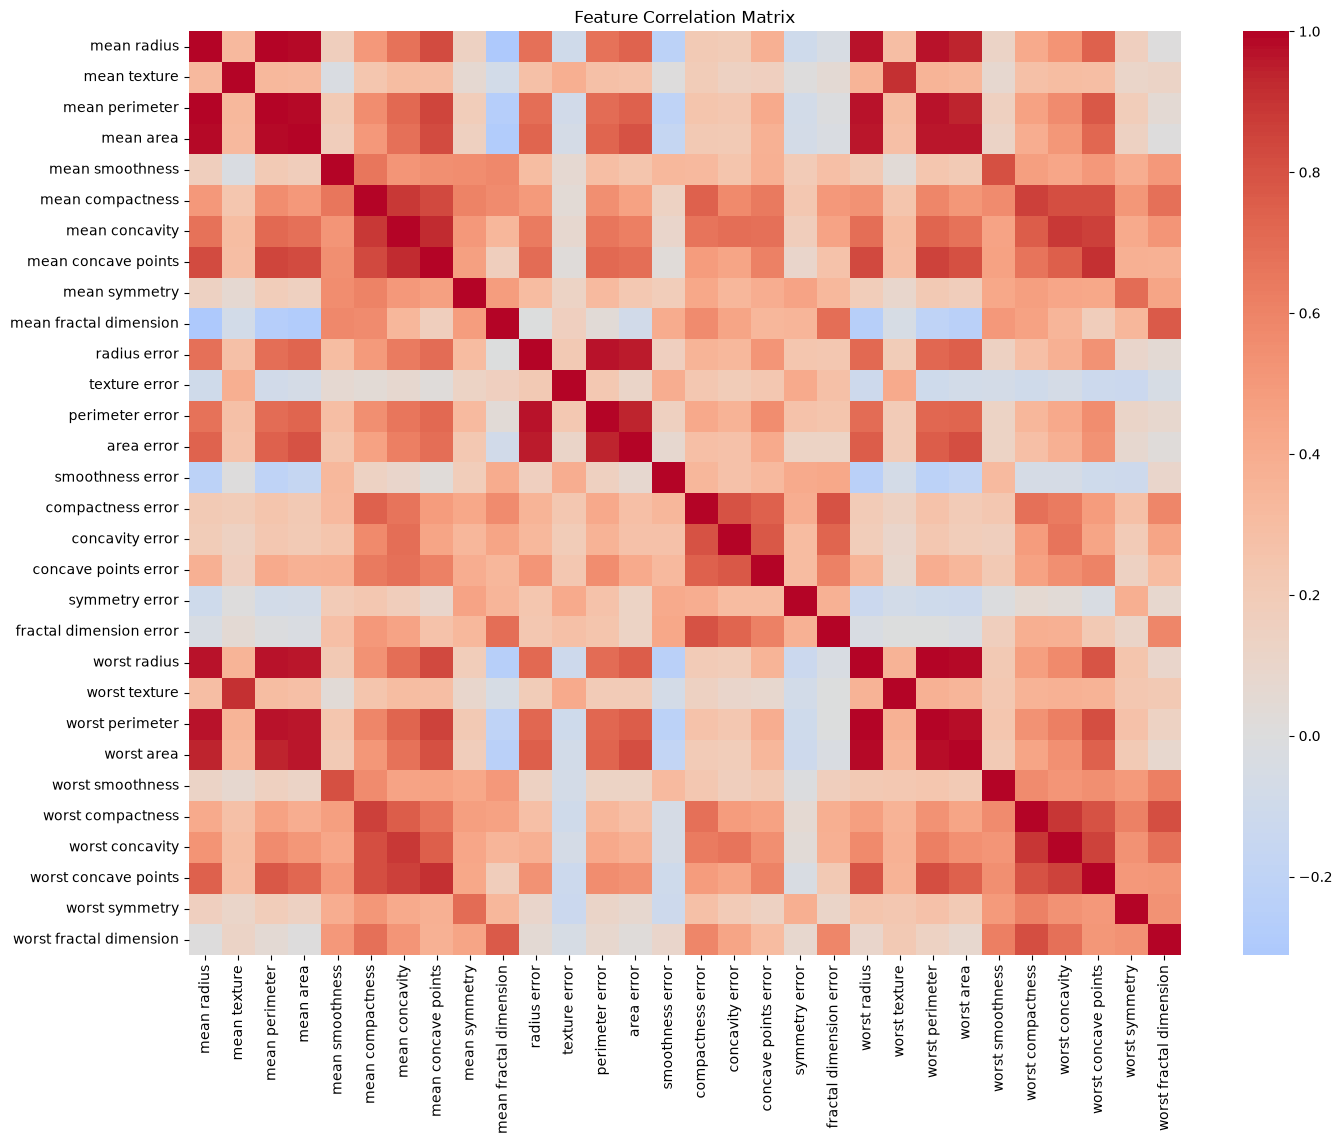

In [12]:
plt.figure(figsize=(16, 12))

correlation_matrix = X.corr()

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0
)

plt.title("Feature Correlation Matrix")
plt.show()

## 2. Train-Test Split and Preprocessing

In [13]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

In [14]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())

Training samples: 455
Testing samples: 114

Training class distribution:
0    285
1    170
Name: count, dtype: int64

Testing class distribution:
0    72
1    42
Name: count, dtype: int64


In [16]:
model_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=5000,
        random_state=42
    ))
])

In [17]:
model_pipeline.fit(X_train, y_train)

print("Logistic Regression training completed!")

Logistic Regression training completed!


In [18]:
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

In [19]:
y_pred = model_pipeline.predict(X_test)

y_prob = model_pipeline.predict_proba(X_test)[:, 1]

In [20]:
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))

Accuracy: 0.9649122807017544
Precision: 0.975
Recall: 0.9285714285714286
F1 Score: 0.9512195121951219


In [21]:
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Benign", "Malignant"]
    )
)

              precision    recall  f1-score   support

      Benign       0.96      0.99      0.97        72
   Malignant       0.97      0.93      0.95        42

    accuracy                           0.96       114
   macro avg       0.97      0.96      0.96       114
weighted avg       0.97      0.96      0.96       114



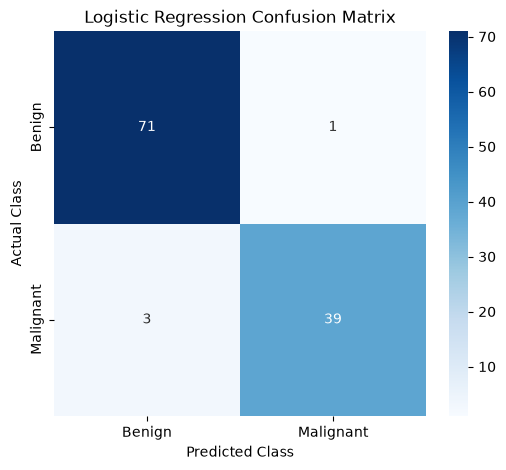

In [22]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Benign", "Malignant"],
    yticklabels=["Benign", "Malignant"]
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Logistic Regression Confusion Matrix")

plt.show()

## 3. Classification Threshold Analysis

In [23]:
y_prob = model_pipeline.predict_proba(X_test)[:, 1]

In [24]:
thresholds = [0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]

threshold_results = []

for threshold in thresholds:

    predictions = (y_prob >= threshold).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(y_test, predictions),
        "F1 Score": f1_score(y_test, predictions),
    })

threshold_df = pd.DataFrame(threshold_results)

threshold_df

,Threshold,Accuracy,Precision,Recall,F1 Score
0,0.2,0.956140,0.911111,0.976190,0.942529
1,0.3,0.982456,0.976190,0.976190,0.976190
2,0.4,0.973684,0.975610,0.952381,0.963855
3,0.5,0.964912,0.975000,0.928571,0.951220
4,0.6,0.964912,1.000000,0.904762,0.950000
5,0.7,0.964912,1.000000,0.904762,0.950000
6,0.8,0.947368,1.000000,0.857143,0.923077


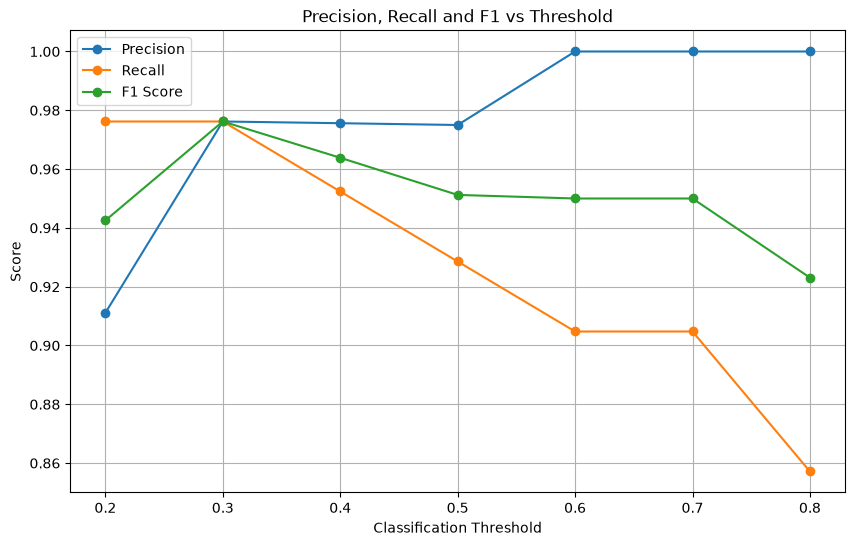

In [25]:
plt.figure(figsize=(10, 6))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["F1 Score"],
    marker="o",
    label="F1 Score"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title("Precision, Recall and F1 vs Threshold")
plt.legend()
plt.grid()
plt.show()

In [33]:
for threshold in thresholds:

    predictions = (y_prob >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test, predictions
    ).ravel()

    print(
        f"Threshold: {threshold:.1f} | "
        f"FP: {fp} | FN: {fn} | "
        f"TP: {tp} | TN: {tn}"
    )

Threshold: 0.2 | FP: 4 | FN: 1 | TP: 41 | TN: 68
Threshold: 0.3 | FP: 1 | FN: 1 | TP: 41 | TN: 71
Threshold: 0.4 | FP: 1 | FN: 2 | TP: 40 | TN: 71
Threshold: 0.5 | FP: 1 | FN: 3 | TP: 39 | TN: 71
Threshold: 0.6 | FP: 0 | FN: 4 | TP: 38 | TN: 72
Threshold: 0.7 | FP: 0 | FN: 4 | TP: 38 | TN: 72
Threshold: 0.8 | FP: 0 | FN: 6 | TP: 36 | TN: 72


## Inference


In [37]:
# Find positions of malignant observations
malignant_indices = np.where(y_test_array == 1)[0]

# Select one malignant observation
record_index = malignant_indices[0]

# Extract its 30 features
new_record = X_test[record_index].reshape(1, -1)

# Actual label
actual_class = y_test_array[record_index]

print("Selected record index:", record_index)
print("Actual class:", actual_class)
print("Number of features:", new_record.shape[1])

Selected record index: 1
Actual class: 1
Number of features: 30


In [38]:
# Predict class
predicted_class = model_pipeline.predict(new_record)[0]

# Predict probabilities
probabilities = model_pipeline.predict_proba(new_record)[0]

class_names = {
    0: "Benign",
    1: "Malignant"
}

print("Actual classification:", class_names[actual_class])
print("Predicted classification:", class_names[predicted_class])

print("\nPrediction probabilities:")
print(f"Benign:    {probabilities[0] * 100:.2f}%")
print(f"Malignant: {probabilities[1] * 100:.2f}%")

print("\nPrediction result:")

if predicted_class == actual_class:
    print("CORRECT PREDICTION")
else:
    print("INCORRECT PREDICTION")

Actual classification: Malignant
Predicted classification: Malignant

Prediction probabilities:
Benign:    0.00%
Malignant: 100.00%

Prediction result:
CORRECT PREDICTION


In [39]:
# Find benign observations in the test set
benign_indices = np.where(y_test_array == 0)[0]

# Select one benign observation
benign_index = benign_indices[0]

# Extract its features
benign_record = X_test[benign_index].reshape(1, -1)

# Actual class
actual_class = y_test_array[benign_index]

# Predict
predicted_class = model_pipeline.predict(benign_record)[0]
probabilities = model_pipeline.predict_proba(benign_record)[0]

class_names = {
    0: "Benign",
    1: "Malignant"
}

print("Actual:", class_names[actual_class])
print("Predicted:", class_names[predicted_class])

print("\nProbabilities:")
print(f"Benign: {probabilities[0] * 100:.2f}%")
print(f"Malignant: {probabilities[1] * 100:.2f}%")

Actual: Benign
Predicted: Benign

Probabilities:
Benign: 99.96%
Malignant: 0.04%


## Compare NumPy and scikit-learn

In [50]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))


def logistic_predict_probability(X, weight, bias):
    z = np.dot(X, weight) + bias
    return sigmoid(z)


def logistic_predict_class(X, weight, bias, threshold=0.5):
    probabilities = logistic_predict_probability(
        X, weight, bias
    )
    return (probabilities >= threshold).astype(int)


def binary_cross_entropy(y_true, y_pred):
    epsilon = 1e-15

    y_pred = np.clip(
        y_pred,
        epsilon,
        1 - epsilon
    )

    loss = -np.mean(
        y_true * np.log(y_pred)
        + (1 - y_true) * np.log(1 - y_pred)
    )

    return loss

In [46]:
def train_logistic_regression(
    X,
    y,
    learning_rate=0.01,
    epochs=1000
):
    n_samples, n_features = X.shape

    weight = np.zeros(n_features)
    bias = 0.0

    loss_history = []

    for epoch in range(epochs):

        probabilities = logistic_predict_probability(
            X, weight, bias
        )

        loss = binary_cross_entropy(y, probabilities)
        loss_history.append(loss)

        errors = probabilities - y

        dw = (X.T @ errors) / n_samples
        db = np.mean(errors)

        weight -= learning_rate * dw
        bias -= learning_rate * db

    return weight, bias, loss_history

In [51]:
print(train_logistic_regression)



<function train_logistic_regression at 0x7cab217920c0>


In [54]:
scratch_weight, scratch_bias, scratch_loss = (
    train_logistic_regression(
        X_train_scaled,
        y_train_array,
        learning_rate=0.01,
        epochs=5000
    )
)

print("Final NumPy training loss:", scratch_loss[-1])
print("Weight shape:", scratch_weight.shape)
print("Bias:", scratch_bias)

Final NumPy training loss: 0.06950471313984168
Weight shape: (30,)
Bias: -0.41168912803587115


In [55]:
# NumPy predictions
scratch_prob = logistic_predict_probability(
    X_test_scaled,
    scratch_weight,
    scratch_bias
)

scratch_pred = (scratch_prob >= 0.5).astype(int)

# Scikit-learn predictions
sklearn_prob = sklearn_unregularized.predict_proba(
    X_test_scaled
)[:, 1]

sklearn_pred = sklearn_unregularized.predict(
    X_test_scaled
)

# Compare predictions
comparison = pd.DataFrame({
    "NumPy Probability": scratch_prob,
    "sklearn Probability": sklearn_prob,
    "NumPy Prediction": scratch_pred,
    "sklearn Prediction": sklearn_pred,
    "Actual": y_test_array
})

comparison.head(10)

,NumPy Probability,sklearn Probability,NumPy Prediction,sklearn Prediction,Actual
0,0.000899,0.000365,0,0,0
1,0.999999,1.000000,1,1,1
2,0.128731,0.042568,0,0,0
3,0.631731,0.576187,1,1,1
4,0.442509,0.509155,0,1,0
5,0.002011,0.000616,0,0,0
6,0.721822,0.761534,1,1,1
7,0.004171,0.001012,0,0,0
8,0.001002,0.000569,0,0,0
9,0.020350,0.010768,0,0,0


In [56]:
comparison_metrics = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1"],
    "NumPy": [
        accuracy_score(y_test_array, scratch_pred),
        precision_score(y_test_array, scratch_pred),
        recall_score(y_test_array, scratch_pred),
        f1_score(y_test_array, scratch_pred)
    ],
    "Scikit-learn": [
        accuracy_score(y_test_array, sklearn_pred),
        precision_score(y_test_array, sklearn_pred),
        recall_score(y_test_array, sklearn_pred),
        f1_score(y_test_array, sklearn_pred)
    ]
})

comparison_metrics

,Metric,NumPy,Scikit-learn
0,Accuracy,0.982456,0.964912
1,Precision,1.000000,0.975000
2,Recall,0.952381,0.928571
3,F1,0.975610,0.951220


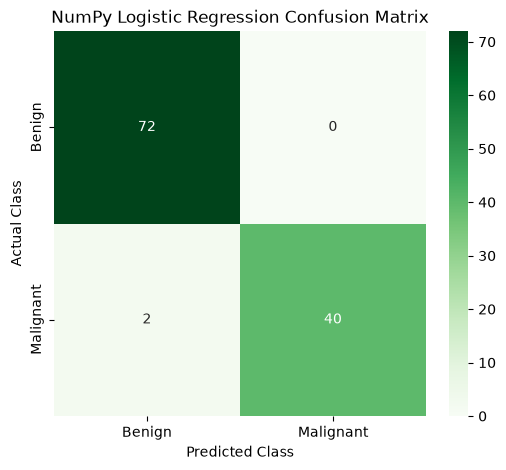

In [57]:
scratch_cm = confusion_matrix(
    y_test_array,
    scratch_pred
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    scratch_cm,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["Benign", "Malignant"],
    yticklabels=["Benign", "Malignant"]
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("NumPy Logistic Regression Confusion Matrix")

plt.show()

In [58]:
# Select a benign observation from the test set
benign_indices = np.where(y_test_array == 0)[0]
benign_index = benign_indices[0]

benign_record = X_test[benign_index].reshape(1, -1)

actual_class = y_test_array[benign_index]

predicted_class = model_pipeline.predict(benign_record)[0]
probabilities = model_pipeline.predict_proba(benign_record)[0]

print("Actual:", "Benign" if actual_class == 0 else "Malignant")
print("Predicted:", "Benign" if predicted_class == 0 else "Malignant")

print(f"Benign probability: {probabilities[0] * 100:.2f}%")
print(f"Malignant probability: {probabilities[1] * 100:.2f}%")

Actual: Benign
Predicted: Benign
Benign probability: 99.96%
Malignant probability: 0.04%
